## IMPORTS

In [1]:
import pandas as pd
import numpy as np

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import torch
import torch.nn as nn
import torch.optim as optim

import matplotlib.pyplot as plt

## Load Data

In [2]:
data = pd.read_csv("train.csv")

data['date'] = pd.to_datetime(data['date'])

store_id = 1
item_id = 1

df = data[
    (data['store'] == store_id) &
    (data['item'] == item_id)
].copy()

df = df.sort_values('date')

sales_data = df['sales'].values.reshape(-1,1)

## SCALE DATA

In [3]:
scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(sales_data)

## CREATE SEQUENCES

In [4]:
sequence_length = 30

X = []
y = []

for i in range(sequence_length, len(scaled_data)):

    X.append(
        scaled_data[i-sequence_length:i]
    )

    y.append(
        scaled_data[i]
    )

X = np.array(X)
y = np.array(y)

## CHECK SHAPES

In [5]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1796, 30, 1)
y shape: (1796, 1)


## TRAIN / VALID SPLIT

In [6]:
split = int(len(X) * 0.8)

X_train = X[:split]
X_valid = X[split:]

y_train = y[:split]
y_valid = y[split:]

## CONVERT TO TENSORS

In [7]:
X_train_tensor = torch.tensor(
    X_train,
    dtype=torch.float32
)

X_valid_tensor = torch.tensor(
    X_valid,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train,
    dtype=torch.float32
)

y_valid_tensor = torch.tensor(
    y_valid,
    dtype=torch.float32
)

## VERIFY SHAPES

In [8]:
print("X_train_tensor:", X_train_tensor.shape)
print("X_valid_tensor:", X_valid_tensor.shape)

print("y_train_tensor:", y_train_tensor.shape)
print("y_valid_tensor:", y_valid_tensor.shape)

X_train_tensor: torch.Size([1436, 30, 1])
X_valid_tensor: torch.Size([360, 30, 1])
y_train_tensor: torch.Size([1436, 1])
y_valid_tensor: torch.Size([360, 1])


## DEFINE LSTM MODEL

In [9]:
class DemandLSTM(nn.Module):

    def __init__(self):

        super(DemandLSTM, self).__init__()

        self.hidden_size = 64

        self.num_layers = 2

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=self.hidden_size,
            num_layers=self.num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(
            self.hidden_size,
            1
        )

    def forward(self, x):

        h0 = torch.zeros(
            self.num_layers,
            x.size(0),
            self.hidden_size
        )

        c0 = torch.zeros(
            self.num_layers,
            x.size(0),
            self.hidden_size
        )

        out, _ = self.lstm(
            x,
            (h0, c0)
        )

        out = out[:, -1, :]

        out = self.fc(out)

        return out

## INITIALIZE MODEL

In [10]:
model = DemandLSTM()

criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

## TRAINING LOOP

In [12]:
epochs = 200

train_losses = []

for epoch in range(epochs):

    model.train()

    outputs = model(X_train_tensor)

    loss = criterion(
        outputs,
        y_train_tensor
    )

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    train_losses.append(loss.item())

    if (epoch + 1) % 10 == 0:

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Loss: {loss.item():.6f}"
        )

Epoch [10/200] Loss: 0.014019
Epoch [20/200] Loss: 0.013556
Epoch [30/200] Loss: 0.013382
Epoch [40/200] Loss: 0.013339
Epoch [50/200] Loss: 0.013301
Epoch [60/200] Loss: 0.013270
Epoch [70/200] Loss: 0.013249
Epoch [80/200] Loss: 0.013237
Epoch [90/200] Loss: 0.013230
Epoch [100/200] Loss: 0.013226
Epoch [110/200] Loss: 0.013224
Epoch [120/200] Loss: 0.013223
Epoch [130/200] Loss: 0.013222
Epoch [140/200] Loss: 0.013221
Epoch [150/200] Loss: 0.013221
Epoch [160/200] Loss: 0.013220
Epoch [170/200] Loss: 0.013220
Epoch [180/200] Loss: 0.013219
Epoch [190/200] Loss: 0.013219
Epoch [200/200] Loss: 0.013218


## LOSS PLOT

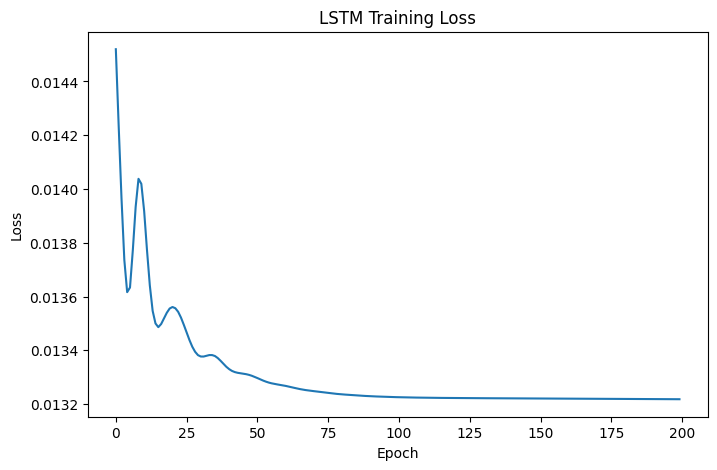

In [13]:
plt.figure(figsize=(8,5))

plt.plot(train_losses)

plt.title("LSTM Training Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.show()

## PREDICTIONS

In [14]:
model.eval()

with torch.no_grad():

    lstm_predictions = model(
        X_valid_tensor
    ).numpy()

## INVERSE SCALING

In [15]:
lstm_predictions_actual = scaler.inverse_transform(
    lstm_predictions
)

y_valid_actual = scaler.inverse_transform(
    y_valid
)

## EVALUATION

In [16]:
lstm_mae = mean_absolute_error(
    y_valid_actual,
    lstm_predictions_actual
)

lstm_rmse = np.sqrt(
    mean_squared_error(
        y_valid_actual,
        lstm_predictions_actual
    )
)

print("LSTM MAE:", lstm_mae)

print("LSTM RMSE:", lstm_rmse)

LSTM MAE: 4.615525155597263
LSTM RMSE: 5.859858811902028


## FORECAST GRAPH

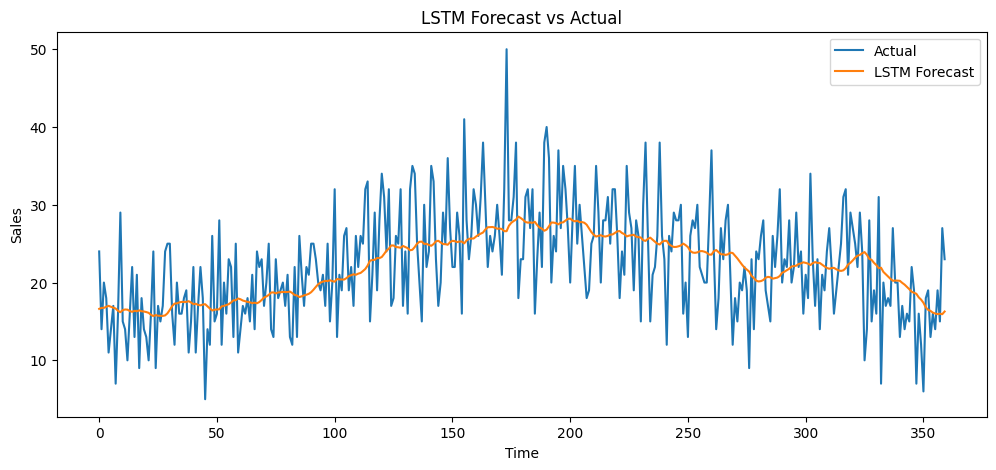

In [17]:
plt.figure(figsize=(12,5))

plt.plot(
    y_valid_actual,
    label="Actual"
)

plt.plot(
    lstm_predictions_actual,
    label="LSTM Forecast"
)

plt.title("LSTM Forecast vs Actual")

plt.xlabel("Time")

plt.ylabel("Sales")

plt.legend()

plt.show()